In [4]:
import sys
sys.path.append("../src")
import cv2, numpy as np, skimage, matplotlib.pyplot as plt
from utils_cv import baca, tampil, statistik, kontras_bercak


# Kode 4.1 Verifikasi konvolusi manual

In [5]:
import time

def konvolusi(img, k):            # fungsi dari slide P4
    kh, kw = k.shape; ph, pw = kh // 2, kw // 2
    pad = np.pad(img.astype(float), ((ph, ph), (pw, pw)), mode="edge")
    out = np.zeros(img.shape)
    for y in range(img.shape[0]):
        for x in range(img.shape[1]):
            out[y, x] = np.sum(pad[y:y+kh, x:x+kw] * k)
    return np.clip(np.round(out), 0, 255).astype(np.uint8)

def konvolusi_sejati(img, k):     # kernel dibalik 180 derajat dahulu
    return konvolusi(img, np.flip(k))

nama = "teh_041.png"
bersih = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nama}"),
                      cv2.COLOR_BGR2GRAY)
md = cv2.imread(f"../data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"../data/sintetis/mask_bercak/{nama}", 0)

for nm, k in {"rerata": np.ones((3, 3)) / 9,
              "asimetris": np.array([[1, 0, -1], [2, 0, -2], [1, 0, -1]], float)
              }.items():
    t0 = time.perf_counter(); a = konvolusi(bersih, k)
    t_manual = time.perf_counter() - t0
    t0 = time.perf_counter()
    b = cv2.filter2D(bersih, -1, k, borderType=cv2.BORDER_REPLICATE)
    t_cv = time.perf_counter() - t0
    beda = np.abs(a.astype(int) - b.astype(int)).max()
    c = konvolusi_sejati(bersih, k)
    beda2 = np.abs(c.astype(int) - b.astype(int)).max()
    print(f"{nm}: selisih manual vs filter2D={beda}, "
          f"sejati vs filter2D={beda2}, "
          f"waktu manual={t_manual:.3f} s, filter2D={t_cv:.5f} s")


rerata: selisih manual vs filter2D=0, sejati vs filter2D=0, waktu manual=1.467 s, filter2D=0.00059 s
asimetris: selisih manual vs filter2D=0, sejati vs filter2D=255, waktu manual=1.445 s, filter2D=0.00036 s


# Kode 4.2 Tabel penapis x derau x PSNR x waktu x KB

In [6]:
import pandas as pd
rng = np.random.default_rng(42)

def derau_gauss(img, sd):
    return np.clip(img + rng.normal(0, sd, img.shape), 0, 255).astype(np.uint8)

def derau_sp(img, p):                  # p = proporsi piksel rusak
    out = img.copy(); m = rng.random(img.shape)
    out[m < p / 2] = 0; out[m > 1 - p / 2] = 255
    return out

def ukur_waktu(f, x, ulang=20):        # rerata beberapa kali, dalam ms
    t = []
    for _ in range(ulang):
        t0 = time.perf_counter(); f(x); t.append(time.perf_counter() - t0)
    return 1000 * np.mean(t)

derau = {"gauss_10": derau_gauss(bersih, 10), "gauss_20": derau_gauss(bersih, 20),
         "gauss_40": derau_gauss(bersih, 40), "sp_4%": derau_sp(bersih, 0.04),
         "sp_10%": derau_sp(bersih, 0.10)}
penapis = {"rerata_3": lambda x: cv2.blur(x, (3, 3)),
           "rerata_5": lambda x: cv2.blur(x, (5, 5)),
           "gauss_5": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
           "median_3": lambda x: cv2.medianBlur(x, 3),
           "median_5": lambda x: cv2.medianBlur(x, 5),
           "median_9": lambda x: cv2.medianBlur(x, 9)}
baris = []
for dn, d in derau.items():
    baris.append([dn, "tanpa", cv2.PSNR(bersih, d), 0.0,
                  kontras_bercak(d, md, mb)])
    for pn, f in penapis.items():
        out = f(d)
        baris.append([dn, pn, cv2.PSNR(bersih, out), ukur_waktu(f, d),
                      kontras_bercak(out, md, mb)])
tabel = pd.DataFrame(baris, columns=["derau", "penapis", "PSNR_dB",
                                     "waktu_ms", "KB"]).round(2)
print(tabel)
tabel.to_csv("../hasil/b4_tabel_penapis.csv", index=False)


       derau   penapis  PSNR_dB  waktu_ms    KB
0   gauss_10     tanpa    28.11      0.00  4.23
1   gauss_10  rerata_3    36.74      0.09  6.84
2   gauss_10  rerata_5    37.01      0.12  6.78
3   gauss_10   gauss_5    37.49      0.16  7.01
4   gauss_10  median_3    35.47      0.06  6.90
5   gauss_10  median_5    38.37      0.39  7.86
6   gauss_10  median_9    38.34      9.77  8.56
7   gauss_20     tanpa    22.14      0.00  2.37
8   gauss_20  rerata_3    31.42      0.09  5.37
9   gauss_20  rerata_5    34.21      0.12  6.15
10  gauss_20   gauss_5    32.54      0.16  5.75
11  gauss_20  median_3    29.72      0.06  4.86
12  gauss_20  median_5    33.41      0.40  6.26
13  gauss_20  median_9    35.37     10.01  6.89
14  gauss_40     tanpa    16.66      0.00  1.22
15  gauss_40  rerata_3    26.02      0.09  3.36
16  gauss_40  rerata_5    29.69      0.11  4.63
17  gauss_40   gauss_5    27.20      0.16  3.76
18  gauss_40  median_3    23.82      0.06  2.80
19  gauss_40  median_5    27.77      0.4

# Grafik PSNR dan waktu komputasi

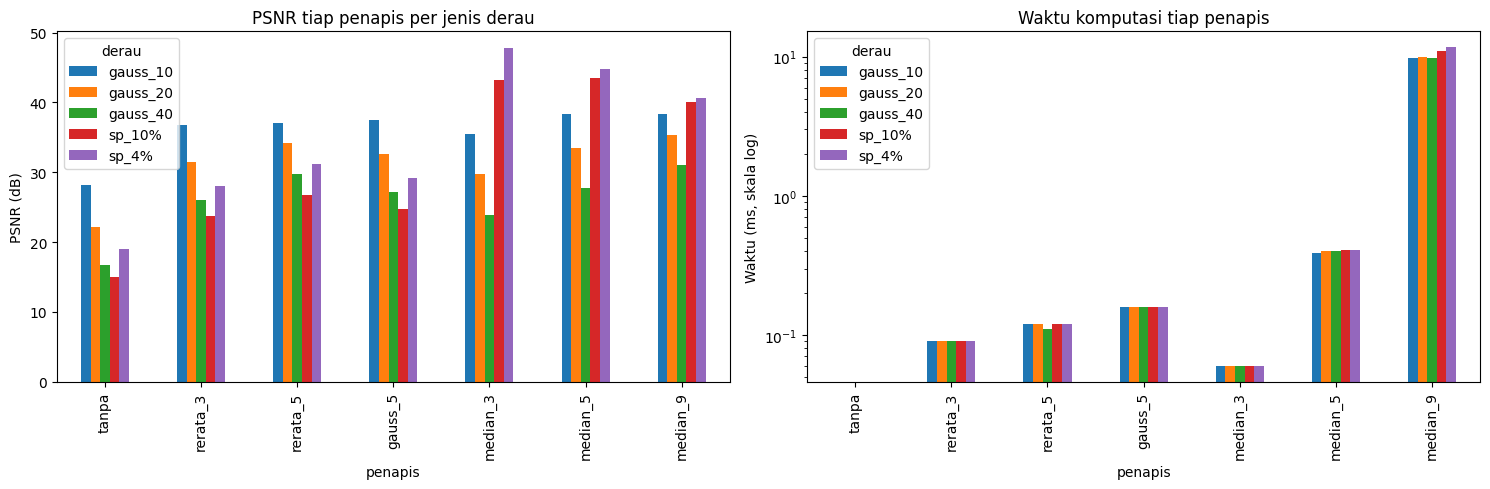

In [7]:
urutan = ["tanpa", "rerata_3", "rerata_5", "gauss_5",
          "median_3", "median_5", "median_9"]
piv_psnr = tabel.pivot(index="penapis", columns="derau",
                       values="PSNR_dB").reindex(urutan)
piv_waktu = tabel.pivot(index="penapis", columns="derau",
                        values="waktu_ms").reindex(urutan)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
piv_psnr.plot.bar(ax=axes[0])
axes[0].set_ylabel("PSNR (dB)")
axes[0].set_title("PSNR tiap penapis per jenis derau")
piv_waktu.plot.bar(ax=axes[1], logy=True)
axes[1].set_ylabel("Waktu (ms, skala log)")
axes[1].set_title("Waktu komputasi tiap penapis")
plt.tight_layout()
plt.savefig("../hasil/b4_grafik_penapis.png", dpi=80)
plt.show()


# Kode 4.3 Pengaruh ukuran kernel median pada bercak kecil

In [8]:
def selisih_rerata(kanal, mask_daun, mask_bercak):
    """dI = |rerata bercak - rerata daun sehat|, dalam satuan intensitas."""
    k = kanal.astype(float)
    sehat = (mask_daun > 0) & (mask_bercak == 0)
    return abs(k[mask_bercak > 0].mean() - k[sehat].mean())

label = pd.read_csv("../data/sintetis/label.csv")
baris = []
for nm in label[label.kelas == "ringan"].nama_file:
    g = cv2.cvtColor(baca(f"../data/sintetis/bersih/{nm}"), cv2.COLOR_BGR2GRAY)
    md2 = cv2.imread(f"../data/sintetis/mask_daun/{nm}", 0)
    mb2 = cv2.imread(f"../data/sintetis/mask_bercak/{nm}", 0)
    for k in [1, 3, 5, 9, 15]:          # k = 1 berarti tanpa penapis
        out = g if k == 1 else cv2.medianBlur(g, k)
        baris.append([nm, k, selisih_rerata(out, md2, mb2),
                      kontras_bercak(out, md2, mb2)])
hasil_median = pd.DataFrame(baris, columns=["nama", "kernel", "dI", "KB"])
print(hasil_median.groupby("kernel")[["dI", "KB"]].mean().round(2))


           dI    KB
kernel             
1       26.01  4.13
3       26.29  4.24
5       24.99  4.09
9       17.81  3.36
15       4.86  1.30


# Grafik dI terhadap ukuran kernel

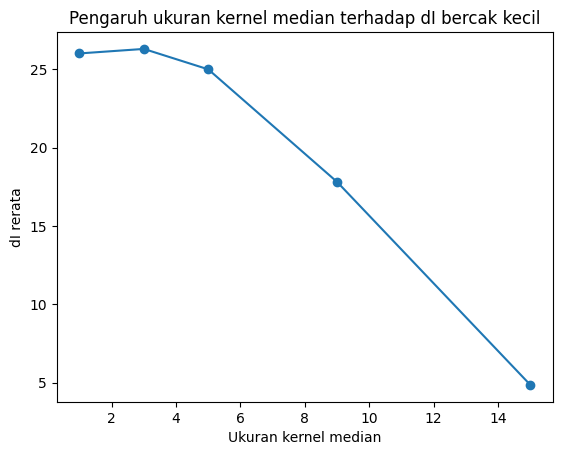

In [9]:
ringkas = hasil_median.groupby("kernel")["dI"].mean()
plt.figure()
plt.plot(ringkas.index, ringkas.values, marker="o")
plt.xlabel("Ukuran kernel median")
plt.ylabel("dI rerata")
plt.title("Pengaruh ukuran kernel median terhadap dI bercak kecil")
plt.savefig("../hasil/b4_grafik_kernel_median.png", dpi=80)
plt.show()


# Potongan bercak teh_021 yang diperbesar

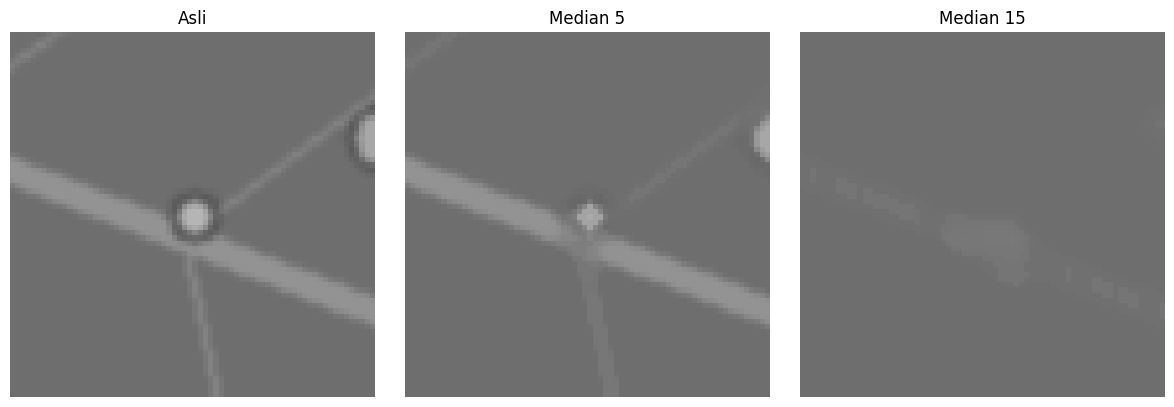

In [10]:
g21 = cv2.cvtColor(baca("../data/sintetis/bersih/teh_021.png"),
                   cv2.COLOR_BGR2GRAY)
cy, cx, r = 319, 441, 35
potong = lambda im: im[cy - r:cy + r, cx - r:cx + r]
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
for ax, im, t in zip(axes,
                     [potong(g21), potong(cv2.medianBlur(g21, 5)),
                      potong(cv2.medianBlur(g21, 15))],
                     ["Asli", "Median 5", "Median 15"]):
    ax.imshow(im, cmap="gray", vmin=0, vmax=255)
    ax.set_title(t)
    ax.axis("off")
plt.tight_layout()
plt.savefig("../hasil/b4_crop_bercak.png", dpi=100)
plt.show()


# Kode 4.4 Pengaruh urutan penajaman

In [11]:
def unsharp(x, k=1.0):
    blur = cv2.GaussianBlur(x, (5, 5), 1.0)
    return cv2.addWeighted(x, 1 + k, blur, -k, 0)

noisy = derau["gauss_20"]
latar = md == 0                         # area latar yang seharusnya rata
for nm, redam in {"Gaussian": lambda x: cv2.GaussianBlur(x, (5, 5), 1.0),
                  "Median": lambda x: cv2.medianBlur(x, 5)}.items():
    A = redam(unsharp(noisy))           # tajamkan dulu, lalu redam
    B = unsharp(redam(noisy))           # redam dulu, lalu tajamkan
    print(f"{nm}: tajam->redam PSNR={cv2.PSNR(bersih, A):.2f} "
          f"sigma_latar={A[latar].std():.1f} | redam->tajam "
          f"PSNR={cv2.PSNR(bersih, B):.2f} sigma_latar={B[latar].std():.1f}")


Gaussian: tajam->redam PSNR=30.40 sigma_latar=7.9 | redam->tajam PSNR=30.22 sigma_latar=8.4
Median: tajam->redam PSNR=30.14 sigma_latar=8.3 | redam->tajam PSNR=31.07 sigma_latar=7.4


# Langkah 4.6 Penapis pilihan pada 12 citra normal

In [12]:
nomor = [1, 6, 11, 16, 21, 26, 31, 36, 41, 46, 51, 56]
baris46 = []
for n in nomor:
    fn = f"teh_{n:03d}.png"
    g = cv2.cvtColor(baca(f"../data/sintetis/citra/{fn}"), cv2.COLOR_BGR2GRAY)
    bb = cv2.cvtColor(baca(f"../data/sintetis/bersih/{fn}"), cv2.COLOR_BGR2GRAY)
    sebelum = cv2.PSNR(bb, g)
    sesudah = cv2.PSNR(bb, cv2.medianBlur(g, 3))
    baris46.append([fn, sebelum, sesudah])
tabel46 = pd.DataFrame(baris46,
                       columns=["citra", "PSNR_sebelum", "PSNR_sesudah"]).round(2)
print(tabel46)
print("Rerata sebelum:", tabel46.PSNR_sebelum.mean().round(2),
      "| sesudah:", tabel46.PSNR_sesudah.mean().round(2))


          citra  PSNR_sebelum  PSNR_sesudah
0   teh_001.png         28.81         36.23
1   teh_006.png         32.83         39.93
2   teh_011.png         34.55         41.27
3   teh_016.png         31.75         38.97
4   teh_021.png         33.68         40.62
5   teh_026.png         31.95         39.08
6   teh_031.png         33.32         40.40
7   teh_036.png         31.34         38.53
8   teh_041.png         31.51         38.58
9   teh_046.png         30.01         37.21
10  teh_051.png         28.68         35.99
11  teh_056.png         33.61         40.49
Rerata sebelum: 31.84 | sesudah: 38.94
